In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from typing import Tuple

df = pd.read_parquet("../data/cisto.parquet")

# 2.1 Raspodjele ključnih varijabli

## Linearna skala

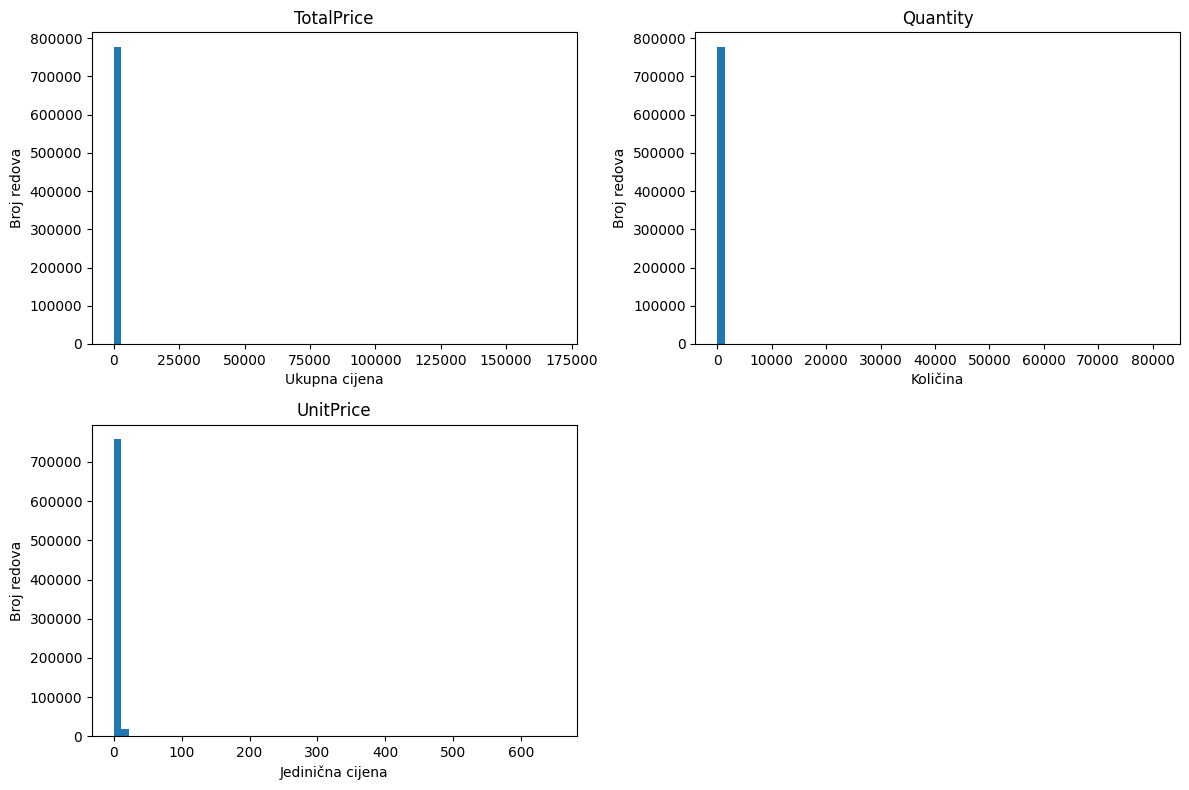

In [38]:
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0]) 

plots = [
    (ax1, "TotalPrice", "Ukupna cijena"),
    (ax2, "Quantity",   "Količina"),
    (ax3, "UnitPrice",  "Jedinična cijena"),
]

for ax, col, label in plots:
    ax.hist(df[col], bins=60)
    ax.set_title(col)
    ax.set_xlabel(label)
    ax.set_ylabel("Broj redova")

fig.tight_layout()
plt.show()

## Logaritamska skala

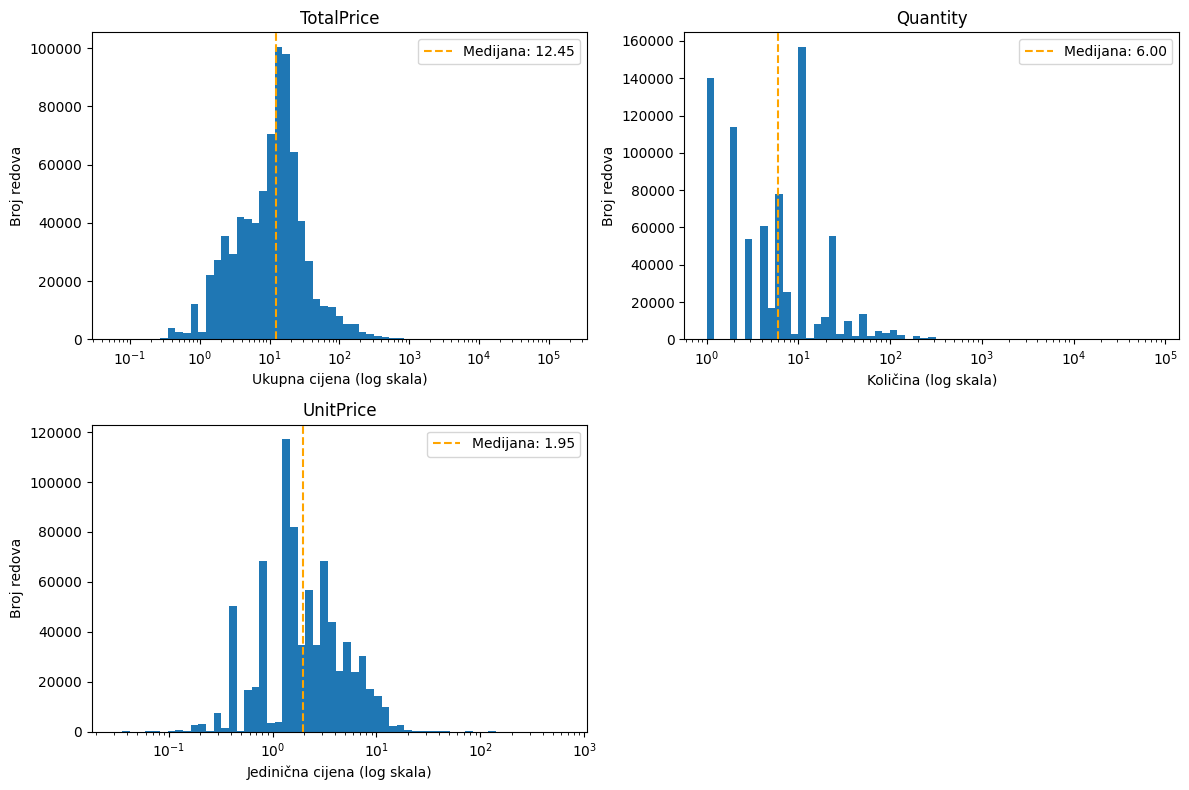

In [39]:
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])  
ax2 = fig.add_subplot(gs[0, 1])   
ax3 = fig.add_subplot(gs[1, 0])   

plots = [
    (ax1, "TotalPrice", "Ukupna cijena"),
    (ax2, "Quantity",   "Količina"),
    (ax3, "UnitPrice",  "Jedinična cijena"),
]

for ax, col, label in plots:
    positive = df[col][df[col] > 0]         
    bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60)
    median = positive.median()

    ax.hist(positive, bins=bins)
    ax.set_xscale("log")
    ax.axvline(median, color="orange", linestyle="--", label=f"Medijana: {median:.2f}")
    ax.set_title(col)
    ax.set_xlabel(f"{label} (log skala)")
    ax.set_ylabel("Broj redova")
    ax.legend()

fig.tight_layout()
plt.show()

## Elementi van granice (Outliers)

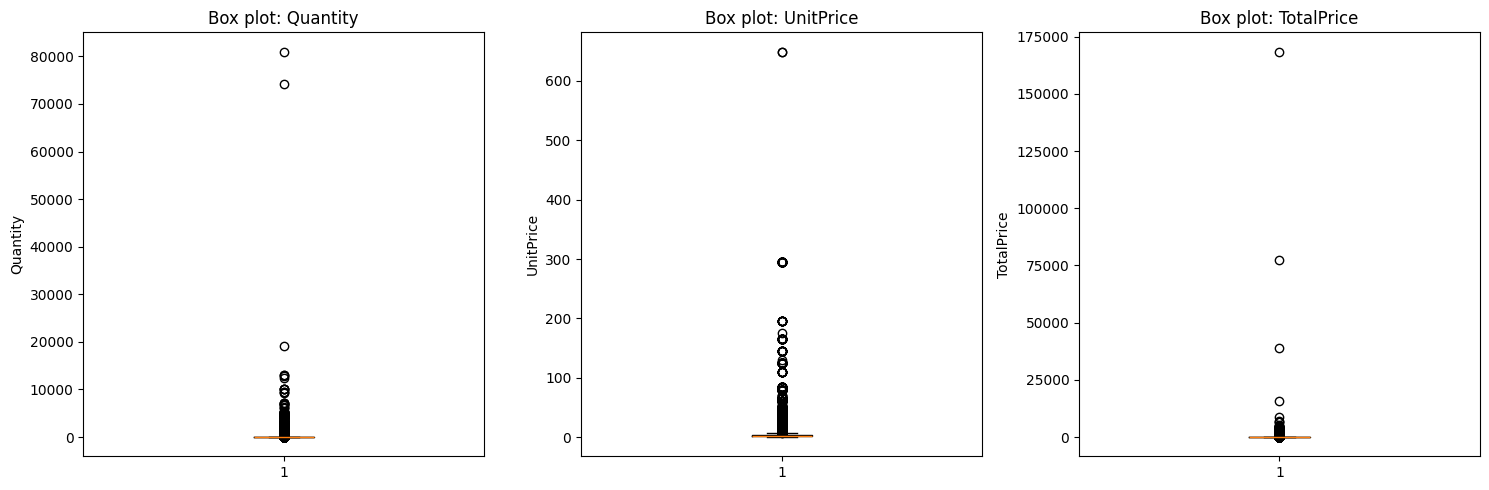

In [40]:
cols = ["Quantity", "UnitPrice", "TotalPrice"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, cols):
    ax.boxplot(df[col].dropna(), vert=True)
    ax.set_title(f'Box plot: {col}')
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

In [41]:
def iqr_outliers(series: pd.Series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)
    return lower, upper, mask.sum(), mask.mean() * 100

results = []
for col in cols:
    lower, upper, n_out, pct = iqr_outliers(df[col])
    results.append({
        'kolona': col,
        'donja_granica': lower,
        'gornja_granica': upper,
        'broj_outliera': n_out,
        'procenat': f"{round(pct, 2)}%"
    })

print(pd.DataFrame(results))

       kolona  donja_granica  gornja_granica  broj_outliera procenat
0    Quantity        -13.000          27.000          51077    6.58%
1   UnitPrice         -2.500           7.500          63131    8.13%
2  TotalPrice        -17.325          42.075          62197    8.01%


## Quantity, UnitPirce, TotalPrice medijana i mean

In [42]:
def get_mean_median(column: str) -> Tuple[float, float]:
    return round(df[column].mean(), 2), round(df[column].median(), 2)

quantity_mean, quantity_median = get_mean_median("Quantity")
unitprice_mean, unitprice_median = get_mean_median("UnitPrice")
totalprice_mean, totalprice_median = get_mean_median("TotalPrice")

print(f"Quantity mean: {quantity_mean}")
print(f"Quantity median: {quantity_median}")

print(f"UnitPrice mean: {unitprice_mean}")
print(f"UnitPrice median: {unitprice_median}")

print(f"TotalPrice mean: {totalprice_mean}")
print(f"TotalPrice median: {totalprice_median}")

Quantity mean: 13.52
Quantity median: 6.0
UnitPrice mean: 2.93
UnitPrice median: 1.95
TotalPrice mean: 21.98
TotalPrice median: 12.45


# 2.2. Top10 TotalPrice stavki

In [43]:
df.nlargest(10, "TotalPrice")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,List,TotalPrice,Godina,Mesec,Datum,DanUNedelji,Sat
776118,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,Year 2010-2011,168469.60,2011,2011-12,2011-12-09,4,9
421804,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,Year 2010-2011,77183.60,2011,2011-01,2011-01-18,1,10
538378,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098,United Kingdom,Year 2010-2011,38970.00,2011,2011-06,2011-06-10,4,15
332011,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,15838,United Kingdom,Year 2009-2010,15818.40,2010,2010-11,2010-11-04,3,11
169271,511465,15044A,PINK PAPER PARASOL,3500,2010-06-08 12:59:00,2.55,18008,United Kingdom,Year 2009-2010,8925.00,2010,2010-06,2010-06-08,1,12
630484,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,2011-09-20 11:05:00,5.06,17450,United Kingdom,Year 2010-2011,7144.72,2011,2011-09,2011-09-20,1,11
417500,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749,United Kingdom,Year 2010-2011,6539.40,2011,2011-01,2011-01-11,1,12
493189,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10,15749,United Kingdom,Year 2010-2011,6539.40,2011,2011-04,2011-04-18,0,13
289757,525968,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,2010-10-08 10:10:00,1.66,15838,United Kingdom,Year 2009-2010,5179.20,2010,2010-10,2010-10-08,4,10
688829,573003,23084,RABBIT NIGHT LIGHT,2400,2011-10-27 12:11:00,2.08,14646,Netherlands,Year 2010-2011,4992.00,2011,2011-10,2011-10-27,3,12


# 2.3 Prodaja po državama

In [44]:
by_countries = (df.groupby("Country")
                .agg(Prihod=("TotalPrice", "sum"),
                     Kupaca=("CustomerID", "nunique"),
                     Racuna=("InvoiceNo", "nunique"))
                .sort_values("Prihod", ascending=False))

by_countries["Udeo %"] = by_countries["Prihod"] / by_countries["Prihod"].sum() * 100
by_countries["ProsecnaKorpa"] = by_countries["Prihod"] / by_countries["Racuna"]
by_countries

,Prihod,Kupaca,Racuna,Udeo %,ProsecnaKorpa
Country,,,,,
United Kingdom,14288773.50,5334,33361,83.713884,428.307710
EIRE,586626.08,3,528,3.436876,1111.034242
Netherlands,549773.41,22,216,3.220967,2545.247269
Germany,383289.00,107,753,2.245582,509.015936
France,309403.16,93,590,1.812706,524.412136
Australia,167800.01,15,89,0.983093,1885.393371
Spain,97766.75,38,144,0.572788,678.935764
Switzerland,93400.94,22,82,0.547210,1139.035854
Sweden,86045.14,19,98,0.504114,878.011633


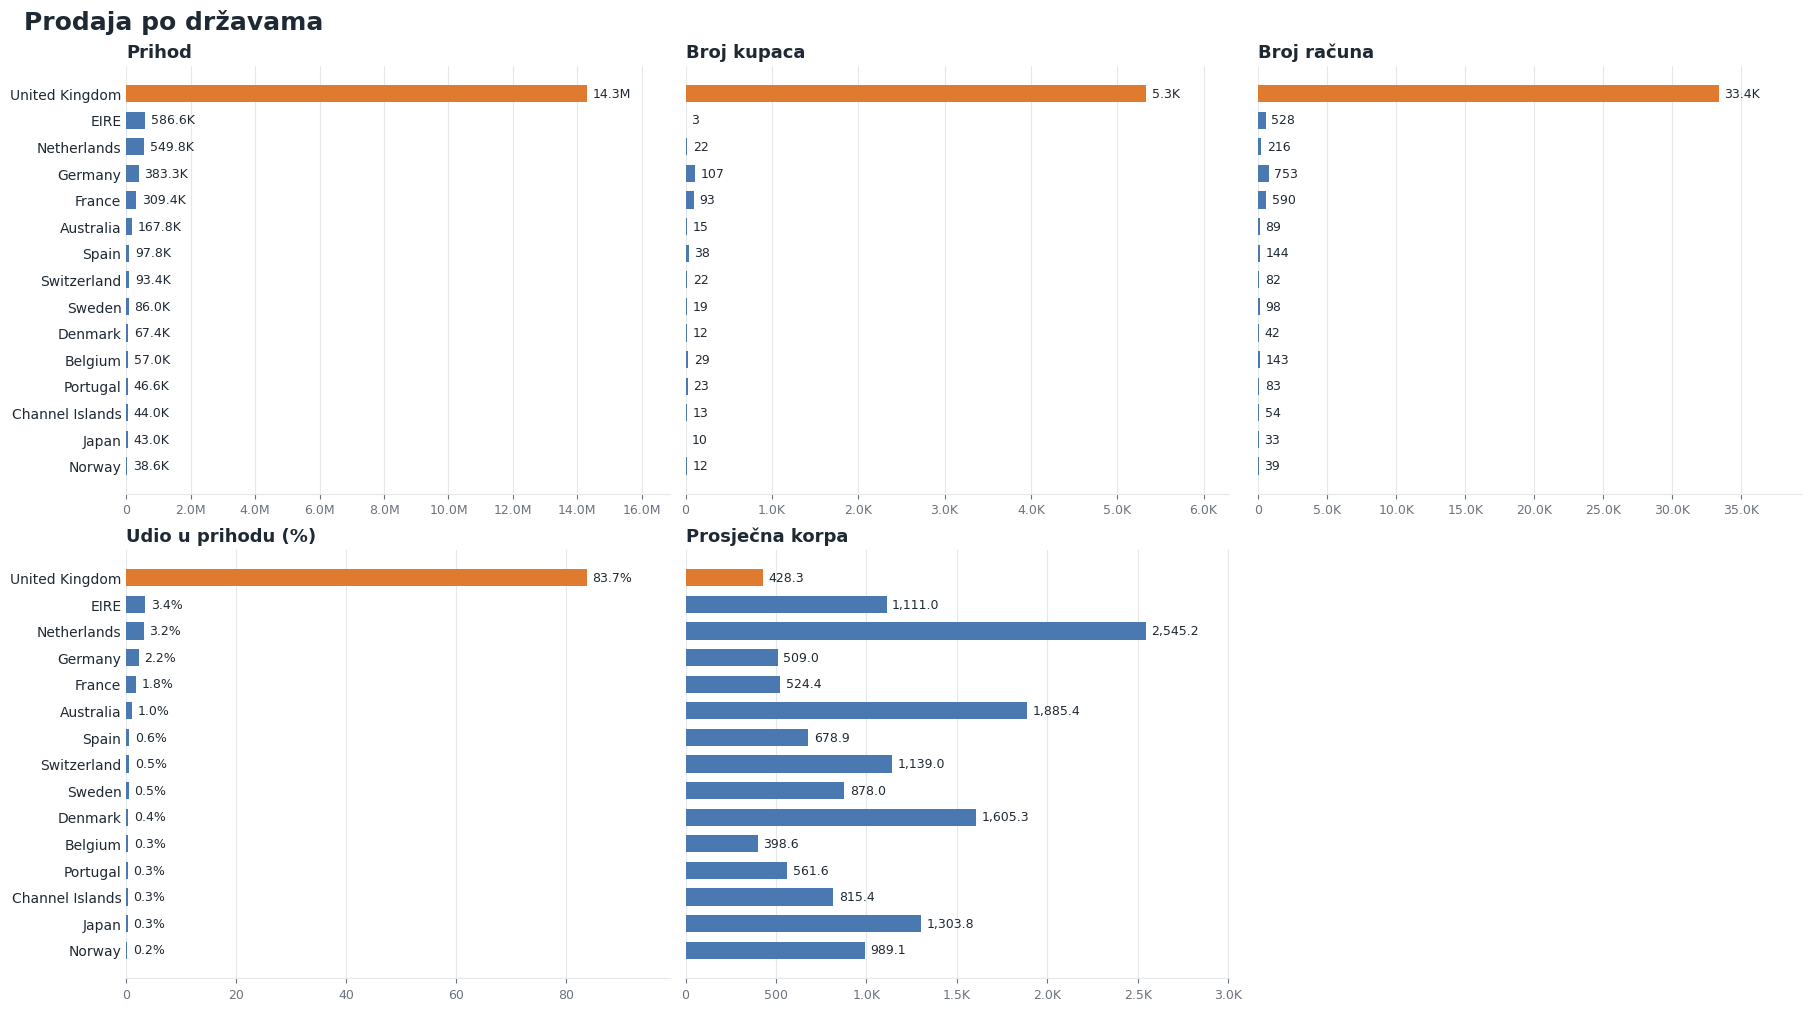

In [45]:
INK = "#1f2933"
MUTED = "#6b7280"
GRID = "#e5e7eb"
BASE = "#4a78b0"
ACCENT = "#e07a2f"


def compact(v):
    for bound, suffix in ((1e6, "M"), (1e3, "K")):
        if abs(v) >= bound:
            return f"{v / bound:,.1f}{suffix}"
    return f"{v:,.0f}"


def draw_by_countries(data: pd.DataFrame, title: str, n: int=15, highlight: str="United Kingdom"):
    d = data.copy()
    d["Udeo %"] = d["Prihod"] / d["Prihod"].sum() * 100
    d = d.sort_values("Prihod", ascending=False).head(n)

    metrics = [
        ("Prihod", "Prihod", compact),
        ("Kupaca", "Broj kupaca", compact),
        ("Racuna", "Broj računa", compact),
        ("Udeo %", "Udio u prihodu (%)", lambda v: f"{v:.1f}%"),
        ("ProsecnaKorpa", "Prosječna korpa", lambda v: f"{v:,.1f}"),
    ]

    colors = [ACCENT if z == highlight else BASE for z in d.index]
    y = np.arange(len(d))

    fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=True, constrained_layout=True)
    axes = axes.ravel()

    for ax, (col, t, fmt) in zip(axes, metrics):
        bars = ax.barh(y, d[col], color=colors, height=0.65)
        ax.bar_label(bars, labels=[fmt(v) for v in d[col]], padding=4, fontsize=9, color=INK)

        ax.set_title(t, loc="left", fontsize=13, fontweight="bold", color=INK)
        ax.margins(x=0.18)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: compact(v)))
        ax.tick_params(axis="x", colors=MUTED, labelsize=9)
        ax.tick_params(axis="y", length=0, labelsize=10, labelcolor=INK)
        ax.set_axisbelow(True)
        ax.xaxis.grid(True, color=GRID, linewidth=0.8)
        for strana in ("top", "right", "left"):
            ax.spines[strana].set_visible(False)
        ax.spines["bottom"].set_color(GRID)

    axes[0].set_yticks(y, d.index)
    axes[0].invert_yaxis() 
    axes[-1].axis("off")

    fig.suptitle(title, fontsize=18, fontweight="bold", color=INK, x=0.01, ha="left")
    plt.show()


draw_by_countries(by_countries, "Prodaja po državama")

## Prodaja po državama bez UK

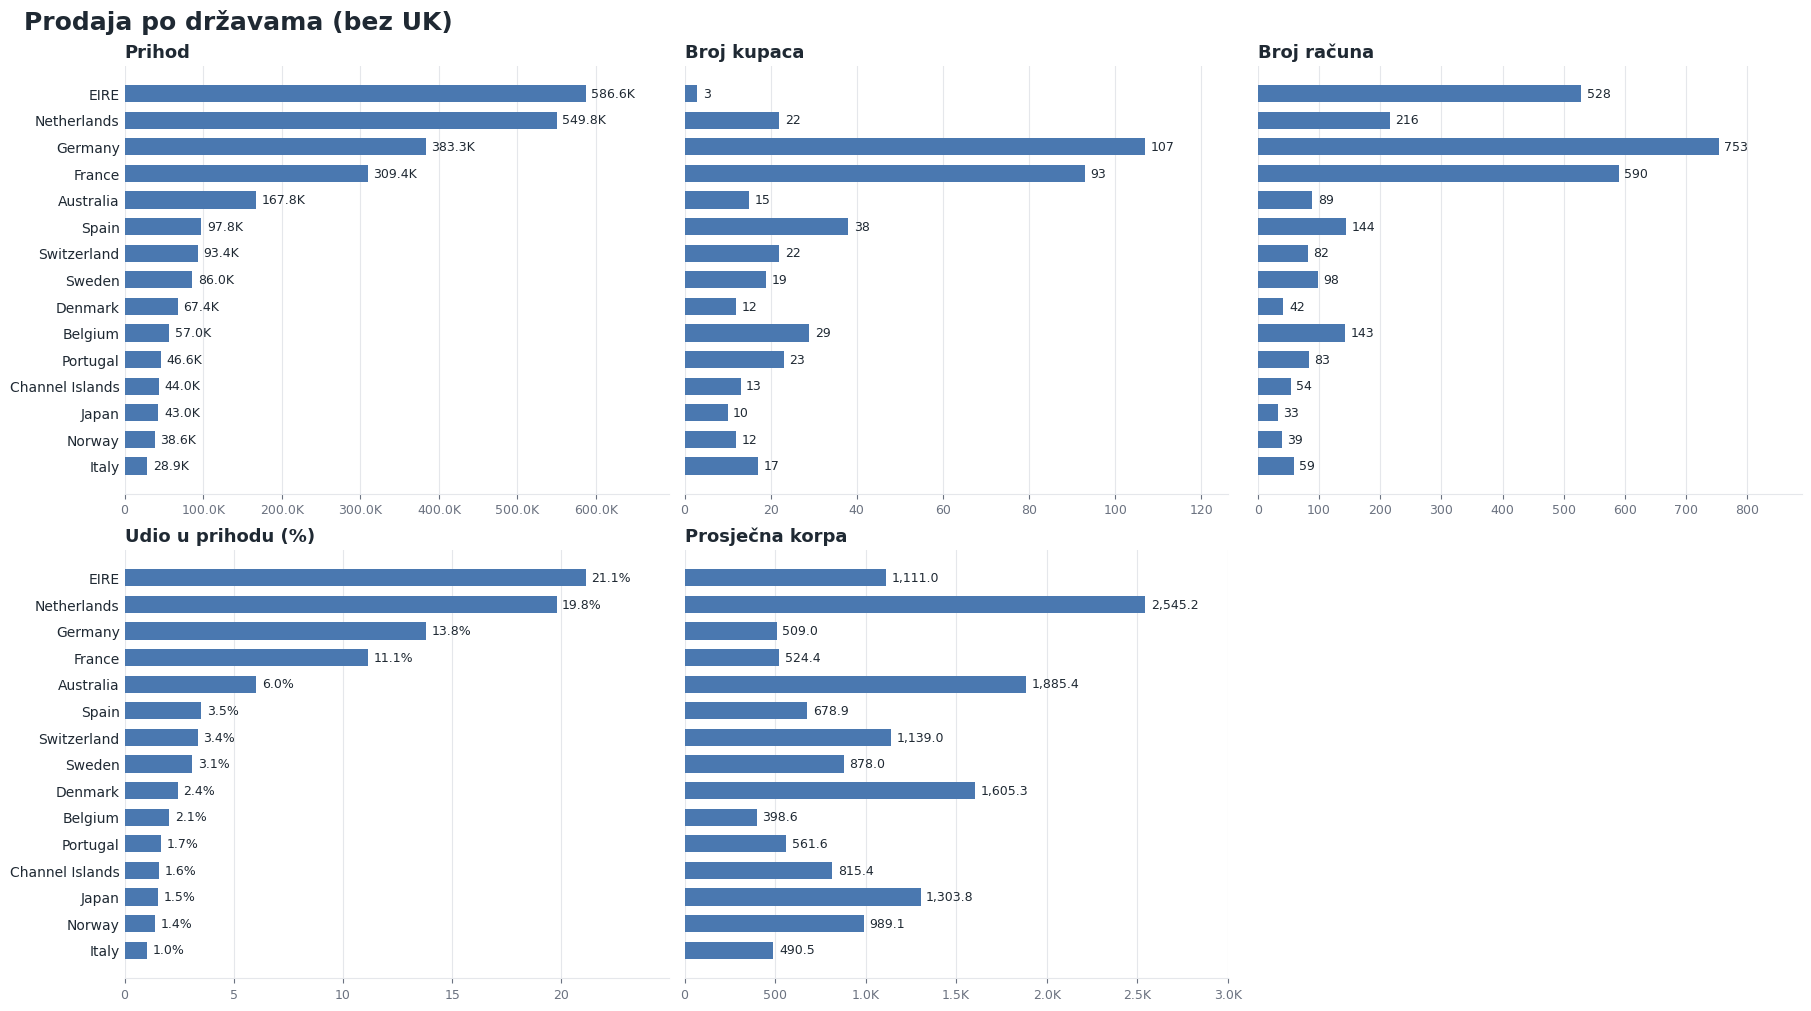

In [46]:
draw_by_countries(by_countries.drop("United Kingdom"), "Prodaja po državama (bez UK)")

# 2.4 Prodaja kroz vrijeme

## Mjesečno

In [47]:
monthly = df.groupby("Mesec")["TotalPrice"].sum().reset_index()
monthly["Datum"] = pd.to_datetime(monthly.Mesec)
print(monthly.tail(4))

      Mesec  TotalPrice      Datum
21  2011-09   938752.63 2011-09-01
22  2011-10  1002326.56 2011-10-01
23  2011-11  1136534.00 2011-11-01
24  2011-12   512228.08 2011-12-01


In [48]:
print(f"Posljednji datum {df['InvoiceDate'].max()}")

Posljednji datum 2011-12-09 12:50:00


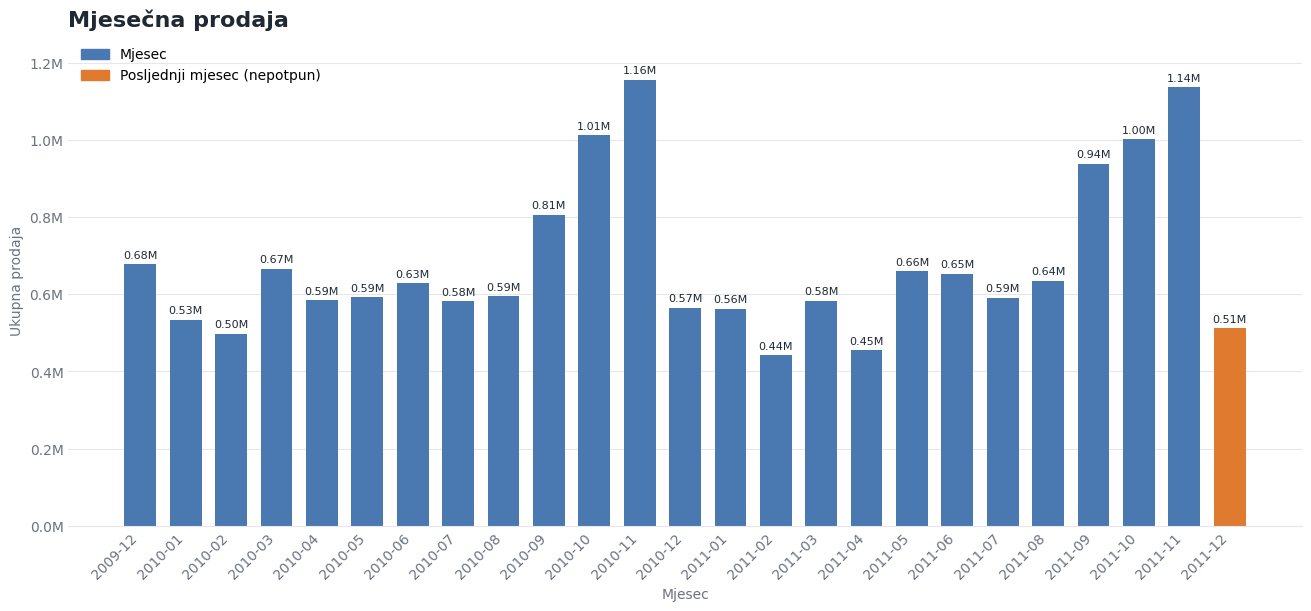

In [49]:
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE, ACCENT = "#4a78b0", "#e07a2f"

monthly = monthly.sort_values("Datum")
last_month = monthly["Datum"].max()

colors = [ACCENT if d == last_month else BASE for d in monthly["Datum"]]
months = monthly["Datum"].dt.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)

bars = ax.bar(months, monthly["TotalPrice"], color=colors, width=0.7)
ax.bar_label(bars, labels=[f"{v / 1e6:.2f}M" for v in monthly["TotalPrice"]],
             padding=3, fontsize=8, color=INK)

ax.set_title("Mjesečna prodaja", loc="left", fontsize=16, fontweight="bold", color=INK)
ax.set_xlabel("Mjesec", color=MUTED)
ax.set_ylabel("Ukupna prodaja", color=MUTED)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M"))
ax.margins(y=0.1)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.tick_params(colors=MUTED, length=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

ax.legend(handles=[Patch(color=BASE, label="Mjesec"),
                   Patch(color=ACCENT, label="Posljednji mjesec (nepotpun)")],
          frameon=False, loc="upper left")

plt.show()

In [50]:
complete_months = monthly.iloc[:-1]      
best = complete_months.loc[complete_months["TotalPrice"].idxmax()]
worst  = complete_months.loc[complete_months["TotalPrice"].idxmin()]
print(f"Najbolji: {best['Mesec']} = {best['TotalPrice']:,.0f}")
print(f"Najgori : {worst['Mesec']} = {worst['TotalPrice']:,.0f}")

Najbolji: 2010-11 = 1,155,978
Najgori : 2011-02 = 442,294


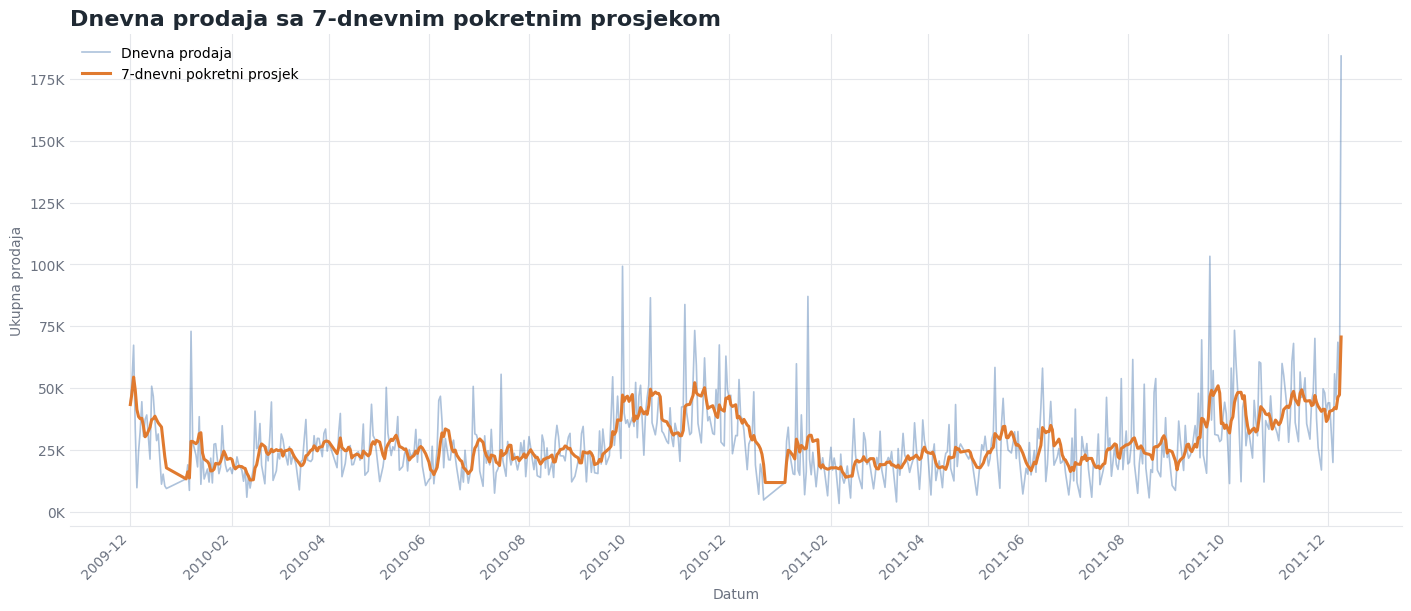

In [52]:
import matplotlib.dates as mdates

INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE, ACCENT = "#4a78b0", "#e07a2f"

daily = df.groupby("Datum")["TotalPrice"].sum().reset_index()
daily["Datum"] = pd.to_datetime(daily["Datum"])
daily = daily.sort_values("Datum").set_index("Datum")

daily["MA7"] = daily["TotalPrice"].rolling("7D").mean()

fig, ax = plt.subplots(figsize=(14, 6), constrained_layout=True)

ax.plot(daily.index, daily["TotalPrice"], color=BASE, alpha=0.45, linewidth=1.2,
        label="Dnevna prodaja")
ax.plot(daily.index, daily["MA7"], color=ACCENT, linewidth=2.2,
        label="7-dnevni pokretni prosjek")

ax.set_title("Dnevna prodaja sa 7-dnevnim pokretnim prosjekom",
             loc="left", fontsize=16, fontweight="bold", color=INK)
ax.set_xlabel("Datum", color=MUTED)
ax.set_ylabel("Ukupna prodaja", color=MUTED)

ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}K"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.tick_params(colors=MUTED, length=0)
ax.set_axisbelow(True)
ax.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

ax.legend(frameon=False, loc="upper left")
plt.show()

# 2.5 Kada kupci kupuju

In [53]:
heat = df.pivot_table(
    index="DanUNedelji",
    columns="Sat",
    values="TotalPrice",
    aggfunc="sum"
)
heat

Sat,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
DanUNedelji,,,,,,,,,,,,,,,
0,NaN,15830.42,88656.82,237882.96,345353.46,330976.96,394910.11,425491.50,327530.18,271870.48,200882.52,64281.70,6561.17,NaN,NaN
1,NaN,11442.26,116586.28,291386.70,493337.31,462704.20,468622.38,424520.49,329702.71,327203.86,205790.85,90813.47,25539.01,14623.87,661.80
2,NaN,10110.76,86149.66,245480.19,449604.98,375196.99,527200.62,418585.11,353035.69,268166.46,177454.05,53796.67,NaN,2893.40,13031.50
3,4.25,15991.41,120349.59,270024.13,450255.33,384592.49,510144.78,386059.38,382707.28,420746.89,247199.23,211473.35,157479.14,105827.29,24956.21
4,NaN,21654.72,106820.20,410011.21,376802.85,318963.26,412261.04,313021.33,293309.34,238901.64,111970.70,54957.16,75.50,373.04,19.19
5,NaN,NaN,NaN,NaN,1059.74,230.20,2110.65,2520.49,1130.93,1599.74,1151.30,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,2853.12,172634.77,310890.43,344772.16,334907.93,236884.34,275958.49,79056.95,NaN,NaN,NaN,NaN


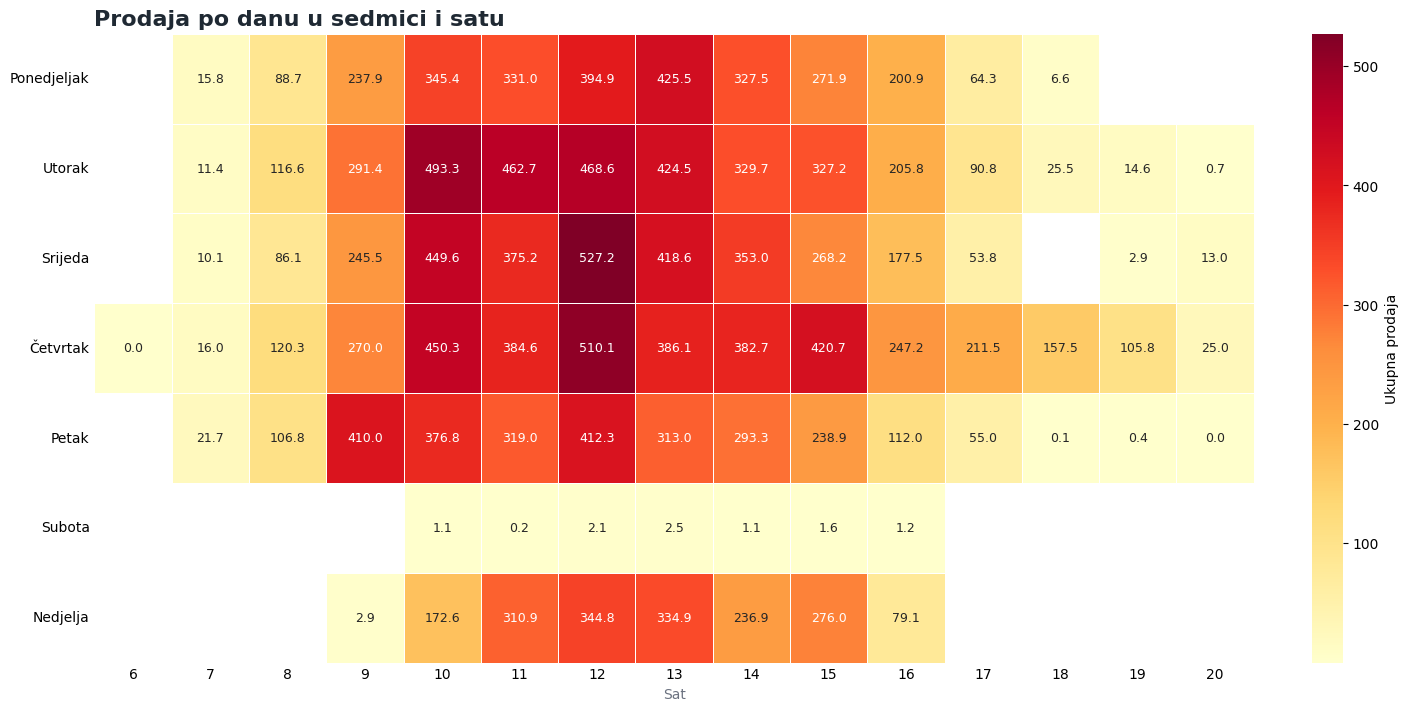

In [54]:
import seaborn as sns

INK, MUTED = "#1f2933", "#6b7280"

days = ["Ponedjeljak", "Utorak", "Srijeda", "Četvrtak", "Petak", "Subota", "Nedjelja"]

heat = df.pivot_table(
    index="DanUNedelji",
    columns="Sat",
    values="TotalPrice",
    aggfunc="sum"
).reindex(range(7))       
heat.index = days          
heat_k = heat / 1000        

fig, ax = plt.subplots(figsize=(14, 7), constrained_layout=True)

sns.heatmap(
    heat_k,
    ax=ax,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    annot_kws={"fontsize": 9},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Ukupna prodaja"}
)

ax.set_title("Prodaja po danu u sedmici i satu", loc="left",
             fontsize=16, fontweight="bold", color=INK)
ax.set_xlabel("Sat", color=MUTED)
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0, length=0)
ax.tick_params(axis="x", length=0)

plt.show()

In [56]:
days = ["Ponedjeljak", "Utorak", "Srijeda", "Četvrtak", "Petak", "Subota", "Nedjelja"]

day_sales = (
    df.groupby("DanUNedelji")["TotalPrice"].sum()
      .rename("Prodaja")
      .reset_index()
)

day_sales["Dan"] = day_sales["DanUNedelji"].map(dict(enumerate(days)))
day_sales["Udio (%)"] = day_sales["Prodaja"] / day_sales["Prodaja"].sum() * 100

day_sales = (
    day_sales[["Dan", "Prodaja", "Udio (%)"]]
    .sort_values("Prodaja", ascending=False)
    .reset_index(drop=True)
)

print(day_sales.to_string(index=False, formatters={
    "Prodaja": "{:,.2f}".format,
    "Udio (%)": "{:.2f}%".format,
}))

        Dan      Prodaja Udio (%)
   Četvrtak 3,687,810.75   21.61%
     Utorak 3,262,935.19   19.12%
    Srijeda 2,980,706.08   17.46%
Ponedjeljak 2,710,228.28   15.88%
      Petak 2,659,141.18   15.58%
   Nedjelja 1,757,958.19   10.30%
     Subota     9,803.05    0.06%


# Odgovori na pitanja — Dan 2

### Pitanje 2.2: Da li su najveće vrednosti greške u podacima ili stvarne kupovine? Kako ste zaključili? Da li ih treba izbaciti?
Najveće pojedinačne stavke (npr. 80.995 komada artikla *PAPER CRAFT , LITTLE BIRDIE* u vrednosti £168.469,60, ili 74.215 komada *MEDIUM CERAMIC TOP STORAGE JAR* u vrednosti £77.352,96) predstavljaju **stvarne veleprodajne (B2B) narudžbine**, a ne tehničke greške.
Zaključujemo po tome što:
- imaju validne brojeve faktura i stvarne šifre registrovanih klijenata,
- cene po komadu odgovaraju regularnim cenovnicima (£1,04–£2,08),
- u sistemu postoje i odgovarajući storno zapisi u istim iznosima za neke transakcije, što potvrđuje formalno administrativno praćenje ugovora.
**Da li ih treba izbaciti?** Ne! One predstavljaju realan novčani tok i legitimne kupce koji nose značajan udeo prometa. Međutim, prilikom klasterovanja i modelovanja maloprodajnih kupaca moramo primeniti logaritamske transformacije ili robusne metode kako ove ekstremne vrednosti ne bi deformisale modele.

### 1. Zašto je prosek `TotalPrice` skoro dvostruko veći od medijane? Koju od te dve mere biste koristili u izveštaju za direktora i zašto?
Prosek (£21,98) je znatno veći od medijane (£12,45) zbog **izrazite desne asimetrije (pozitivnog skew-a)**. Veliki broj malih maloprodajnih kupovina koncentrisan je oko £10–£15, dok manji broj velikih B2B porudžbina (stotine i hiljade funti) snažno vuče aritmetičku sredinu naviše.
U izveštaju za direktora treba prikazati **obe mere uz jasno objašnjenje**:
- **Medijanu** (£12,45) kao realan opis tipične potrošačke korpe prosečnog pojedinačnog kupca.
- **Prosek** (£21,98) kao meru ukupnog obima prodaje pod uticajem ključnih velikih naručilaca.

### 2. Irska i Holandija su visoko po prihodu ali imaju vrlo malo kupaca. Šta zaključujete o tome kakvi su to kupci?
Irska (EIRE) sa samo 3 kupca ostvaruje preko £586.000 prihoda (prosečna korpa po računu £1.111, po kupcu preko £195.000), dok Holandija sa 22 kupca generiše preko £549.000 (prosečna korpa £2.545, po kupcu skoro £25.000), u poređenju sa Velikom Britanijom gde je prosečna korpa £428.
**Zaključak:** Kupci iz Holandije i Irske nisu krajnji potrošači (B2C), već **veliki distributeri, lanci prodavnica ili veleprodaje (B2B)** koji periodično naručuju robu na palete.

### 3. Da li postoji sezonalnost? Da li se obrazac ponavlja obe godine? Zašto je ponavljanje bitno za zaključak?
Da, u podacima je prisutna izrazita **Q4 sezonalnost**. Prodaja stabilno raste tokom rane jeseni (septembar), kulminira u oktobru i novembru (oko £1,15M mesečno), a zatim naglo pada u januaru i dostiže godišnji minimum u februaru (£442K–£497K).
Ovaj obrazac se **dosledno ponavlja i u 2010. i u 2011. godini**. Ponavljanje je ključno jer potvrđuje postojanje stabilnog sezonskog poslovnog ciklusa (priprema maloprodaje za božićne i novogodišnje praznike), a eliminiše pretpostavku o slučajnim fluktuacijama ili izolovanoj marketinškoj kampanji.

### 4. Šta se dešava subotom? Da li je to greška u podacima?
Subotom je zabeleženo samo 400 redova i svega £9.803 prometa (~0,06% ukupnog prihoda).
Ovo **nije greška u podacima**, već poslovna i operativna politika kompanije: skladište, logistika i korisnička podrška subotom nisu radili obradu narudžbina. Već u nedelju obrada se nastavlja sa redovnim prihodom od preko £1,75M (10,3% ukupnog prihoda).

### 5. U koje doba dana se kupuje i šta to govori o tipu kupaca?
Heatmapa pokazuje da se glavnina prodaje realizuje **radnim danima između 09:00 i 16:00 časova**, sa pikom između 11:00 i 14:00. Pre 08:00 i posle 17:00 aktivnost je zanemarljiva.
Ovakav raspored kupovine unutar klasičnog radnog vremena direktno potvrđuje da su dominantni kupci **zaposleni u firmama i vlasnici malih biznisa** koji nabavku vrše tokom radnog vremena, a ne fizička lica u večernjim časovima kod kuće.
